# 00 · Why test a trading idea?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/00_why_test_a_trading_idea.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

A 20-minute primer. **No strategy is tested here.** By the end you can say what a trading strategy is, what a backtest can and cannot tell you, and what $10,000 in the US stock market became over ten years. That last number is the bar every later idea has to beat.

**What you'll do (~20 min):**
1. Learn what a trading strategy is, and why it must be written exactly
2. See why we test ideas on old prices first
3. Meet eight words, no more
4. Work out the first benchmark: what buy and hold made
5. Write a strategy of your own in plain words (no code)

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/aurvyl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. What a trading strategy is

A **trading strategy** is a set of rules that says what to hold and when. **Algorithmic trading** means the rules are written so exactly that a computer can follow them, instead of deciding by gut feeling.

"Exactly" is the whole point. The same idea written two ways:

| Vague | Exact |
|---|---|
| "Buy when the market looks strong." | "Hold SPY on any day its close is above its average close of the last 50 days. Otherwise hold cash." |
| "Sell if it drops a lot." | "Sell at the close if the price is 10% below the highest close since I bought." |
| "Don't take too much risk." | "Never hold more than 40% of the money in one fund." |

The vague versions feel like strategies, but nobody, human or computer, can follow them the same way twice. **A strategy you cannot write exactly cannot be tested.**

## 2. Why we test on old prices first

A **backtest** replays your rules on past prices, as if you had followed them every day, and measures what would have happened. It is cheap: a bad idea costs you an afternoon instead of your savings.

A backtest cannot tell you the future. It can tell you what would have happened, and, if you are careful, how likely that result was to be luck. Most of this workshop is about being careful.

## How an idea becomes a real trade

1. **Idea**: a hunch about how prices behave, such as "prices that are rising tend to keep rising".
2. **Rules**: the hunch made exact, as in the table above.
3. **Backtest**: replay the rules on history and measure the result honestly.
4. **Paper trading**: run the rules on live prices with pretend money.
5. **Live trading**: real money, small at first, watched closely.

**Most ideas die at step 3, and that is the point.** A good backtest is a way to be wrong cheaply.

## Who does this

- **Quant hedge funds and asset managers** run rule-based strategies at large scale.
- **Banks** use algorithms to carry out big client orders and to manage risk.
- **Market makers** keep quoting buy and sell prices and earn the gap between them.
- **Individuals** with Python and free data can test ideas, as you are about to.

## 3. Eight words to start with

Every other term is explained in the notebook where you first need it. The full list is in [`docs/glossary.md`](https://github.com/aurvyl/qm-fintech-quant-workshop/blob/main/docs/glossary.md).

- **Ticker**: the short code for something you can trade, such as `SPY` or `AAPL`.
- **ETF**: an exchange-traded fund, one ticker that holds a whole basket. SPY holds the roughly 500 companies of the S&P 500.
- **Adjusted price**: price history rewritten so stock splits and dividends do not show up as fake jumps.
- **Return**: the percentage change in value. Going from 100 to 105 is a +5% return.
- **Strategy**: the complete set of exact rules that turns data into what to hold.
- **Backtest**: a simulation of how a strategy would have done on past data.
- **Benchmark**: the simple alternative you compare against. Here it is buying the asset and holding it.
- **Transaction cost**: fees and price gaps you pay every time you trade.

## 4. The first number: what buy and hold made

**Buy and hold** is the laziest strategy there is: buy once on day one and never trade. It is the benchmark for everything that follows. If a strategy cannot beat doing nothing, it is not worth the effort.

Run the next cell to load ten years of SPY prices. Each row is one trading day: the **O**pen, **H**igh, **L**ow and **C**lose price, and the **V**olume of shares traded.

In [2]:
from backtester import load_prices

spy = load_prices("SPY")
spy.tail()

,Open,High,Low,Close,Volume
Date,,,,,
2026-10-05,769.69,776.61,769.63,774.83,44840200
2026-10-06,778.15,781.62,777.96,779.09,36054300
2026-10-07,775.77,779.10,773.61,777.22,30989200
2026-10-08,774.86,777.09,770.44,773.93,40431100
2026-10-09,776.24,779.42,775.14,778.57,22596500


**Predict first:** you put $10,000 into SPY on the first day of the data and never touched it. What is it worth on the last day? Write your guess down, then run the cell below.

In [3]:
first, last = spy["Close"].iloc[0], spy["Close"].iloc[-1]
print(f"From {spy.index[0]:%d %b %Y} to {spy.index[-1]:%d %b %Y}")
print(f"$10,000 in SPY became ${10_000 * last / first:,.0f}")

From 04 Jan 2016 to 09 Oct 2026
$10,000 in SPY became $46,055


The picture is more honest than the number. The cell below draws what $10,000 was worth on every day. Look for the drops: 2020 and 2022 are the two big ones. Someone who held through them had to sit through a loss on screen before the recovery. Notebook 01 measures exactly how bad those drops were.

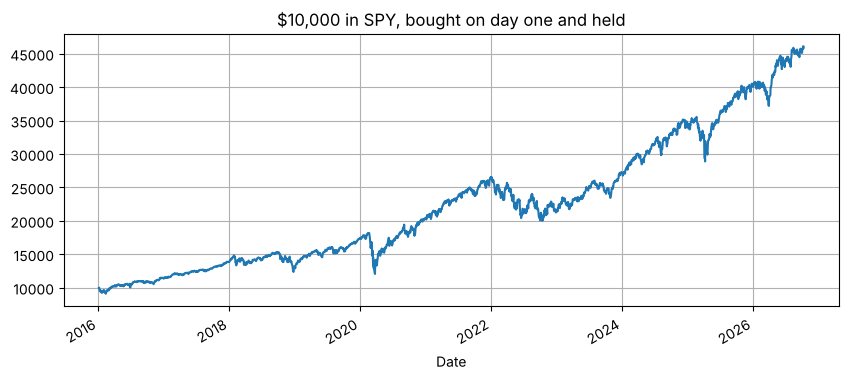

In [4]:
growth = 10_000 * spy["Close"] / spy["Close"].iloc[0]
growth.plot(figsize=(10, 4), title="$10,000 in SPY, bought on day one and held", grid=True)
plt.show()

## 5. ✏️ Your turn: write a strategy in words

No code. On paper or in the notebook, answer these four questions for **one idea of your own**. Make each answer exact enough that a friend following it would reach the same decision as you.

| Question | Example answer |
|---|---|
| What do I look at? | SPY's closing price and its average closing price over the last 50 days. |
| When do I hold? | On any day the close is above the 50-day average. |
| What do I do otherwise? | Hold cash. |
| How often do I check? | Once a day, after the close. |

Keep your answer. In session 5 you will turn it into code and test it with the tools from sessions 2 to 4.

**Check yourself:**
- Why can "buy when the market looks strong" not be backtested?
- A friend says their strategy made 40% last year. Which three questions do you ask before you are impressed? (Hint: compared with what? How many trades? Tested on prices they had not already looked at?)
- A backtest shows a strategy never lost money. Does that prove it is safe?

> Educational use only. Simulated results on historical data; not financial advice.

### Next: how much did it make, and how bumpy was the ride?

Returns, compounding, volatility, the worst fall and the Sharpe ratio, on real prices.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/01_returns_and_risk.ipynb) `01_returns_and_risk.ipynb`